# 02 · Exploratory Data Analysis
**Saudi Tourism & Hospitality Establishments Analytics – Q2 2026**

Eight analysis themes, 12 charts. Under every chart there is a short business reading whose numbers are computed from the data in the same cell (nothing is typed by hand).

In [1]:

import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import Markdown, display
ROOT = Path.cwd().parent; D = ROOT/'data'/'processed'; CH = ROOT/'reports'/'charts'; CH.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK, INK2, MUTED, GRID, SURF = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
HOT, APT, ALL = 'Hotels', 'Serviced apartments & other', 'All facilities'
sns.set_theme(style='white')
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110, 'savefig.dpi': 160,
    'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': INK2,
    'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 14})
def finish(ax, name, grid='y', sub=None):
    if grid: ax.grid(axis=grid, color=GRID, lw=0.8); ax.set_axisbelow(True)
    if sub: ax.set_title(ax.get_title(), pad=24); ax.text(0, 1.02, sub, transform=ax.transAxes, color=INK2, fontsize=9.5)
    ax.figure.tight_layout(); ax.figure.savefig(CH/name, bbox_inches='tight'); plt.show()
def note(t): display(Markdown('> **What it means for the business:** ' + t))
pct = lambda v, d=1: f'{v*100:.{d}f}%'
q = pd.read_csv(D/'Fact_Quarterly.csv').merge(pd.read_csv(D/'Dim_Quarter.csv'), on='Quarter_Key')
reg = pd.read_csv(D/'Fact_Regional_Hospitality.csv'); regm = pd.read_csv(D/'Fact_Regional_Monthly.csv')
city = pd.read_csv(D/'Fact_City_Hospitality.csv')
ea = pd.read_csv(D/'Fact_Employment_Activity.csv').merge(pd.read_csv(D/'Dim_Activity.csv'), on='Activity')
er = pd.read_csv(D/'Fact_Employment_Region.csv')
sa = pd.read_csv(D/'Fact_Establishments_Activity.csv').merge(pd.read_csv(D/'Dim_Activity.csv'), on='Activity')
sr = pd.read_csv(D/'Fact_Establishments_Region.csv')
rh, ra = reg[reg.Facility_Type == HOT].set_index('Region'), reg[reg.Facility_Type == APT].set_index('Region')
last, yago = q.iloc[-1], q.iloc[-5]


## 1. Quarterly trends
### 1.1 Tourism establishments keep growing

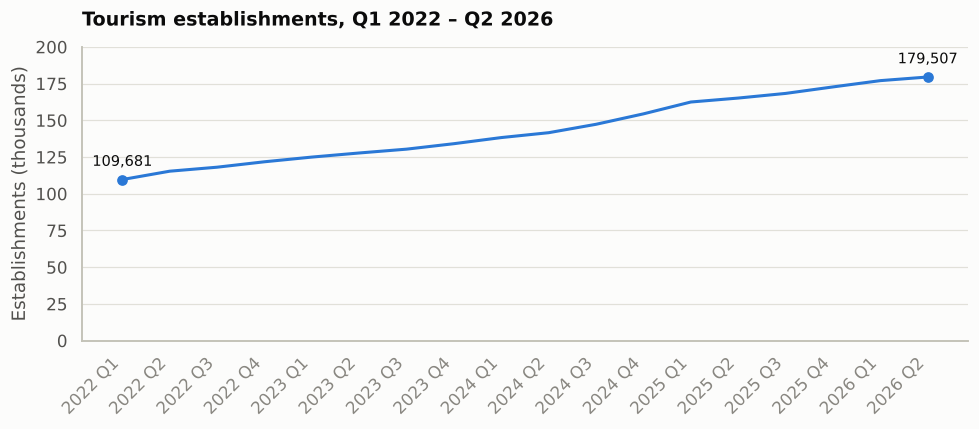

> **What it means for the business:** The sector added 69,826 establishments in 4.25 years (+63.7%), with no quarter of decline. Year-on-year growth to Q2 2026 is +8.7%: still expanding, but the supply base is now large, so demand has to keep pace for each establishment to stay busy.

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q.Quarter_Label, q.Tourism_Establishments/1000, color=BLUE, lw=2)
ax.scatter(q.Quarter_Label.iloc[[0,-1]], q.Tourism_Establishments.iloc[[0,-1]]/1000, color=BLUE, s=36, zorder=3)
for i in (0, -1): ax.annotate(f'{q.Tourism_Establishments.iloc[i]:,.0f}', (q.Quarter_Label.iloc[i], q.Tourism_Establishments.iloc[i]/1000), textcoords='offset points', xytext=(0, 9), ha='center', color=INK, fontsize=9.5)
ax.set_title('Tourism establishments, Q1 2022 – Q2 2026'); ax.set_ylabel('Establishments (thousands)'); ax.set_ylim(0, 200)
plt.xticks(rotation=45, ha='right'); finish(ax, '01_establishments_trend.png')
g_total = last.Tourism_Establishments/q.Tourism_Establishments.iloc[0]-1; g_yoy = last.Tourism_Establishments/yago.Tourism_Establishments-1
note(f'The sector added {last.Tourism_Establishments-q.Tourism_Establishments.iloc[0]:,.0f} establishments in 4.25 years (+{pct(g_total)}), with no quarter of decline. Year-on-year growth to Q2 2026 is +{pct(g_yoy)}: still expanding, but the supply base is now large, so demand has to keep pace for each establishment to stay busy.')

### 1.2 Occupancy: hotels swing with the season, apartments are steadier

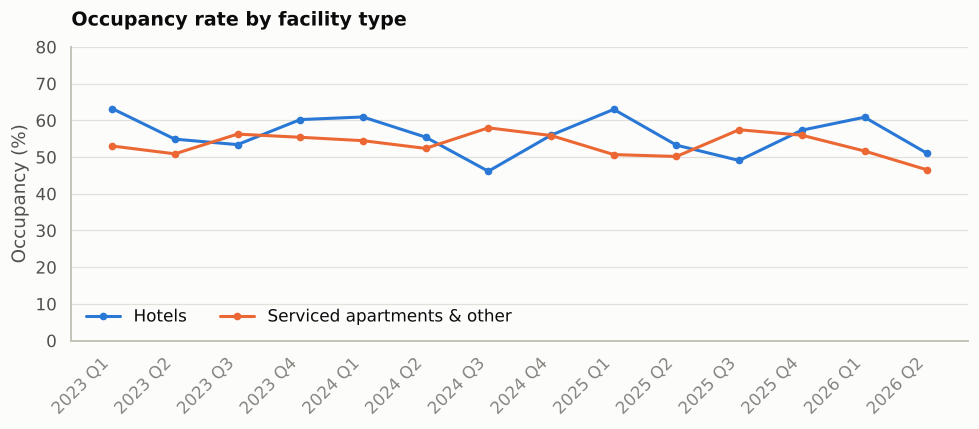

> **What it means for the business:** Hotel occupancy in Q2 2026 is 51.0% versus 53.2% a year earlier (-2.2 pts); serviced apartments are at 46.5% (-3.7 pts), their lowest value in the series (min = 46.5%). Hotels range 46.1%–63.2% across quarters, apartments 46.5%–58.0%. Occupancy is falling while the number of facilities rises, a sign that supply is growing faster than room demand.

In [3]:
fig, ax = plt.subplots(figsize=(9, 4)); d = q.dropna(subset=['Occupancy_Hotels'])
ax.plot(d.Quarter_Label, d.Occupancy_Hotels*100, color=BLUE, lw=2, marker='o', ms=4, label=HOT)
ax.plot(d.Quarter_Label, d.Occupancy_Apartments*100, color=ORANGE, lw=2, marker='o', ms=4, label=APT)
ax.set_title('Occupancy rate by facility type'); ax.set_ylabel('Occupancy (%)'); ax.set_ylim(0, 80); ax.legend(frameon=False, loc='lower left', ncol=2)
plt.xticks(rotation=45, ha='right'); finish(ax, '02_occupancy_trend.png')
note(f'Hotel occupancy in Q2 2026 is {pct(last.Occupancy_Hotels)} versus {pct(yago.Occupancy_Hotels)} a year earlier ({(last.Occupancy_Hotels-yago.Occupancy_Hotels)*100:+.1f} pts); serviced apartments are at {pct(last.Occupancy_Apartments)} ({(last.Occupancy_Apartments-yago.Occupancy_Apartments)*100:+.1f} pts), their lowest value in the series (min = {pct(d.Occupancy_Apartments.min())}). Hotels range {pct(d.Occupancy_Hotels.min())}–{pct(d.Occupancy_Hotels.max())} across quarters, apartments {pct(d.Occupancy_Apartments.min())}–{pct(d.Occupancy_Apartments.max())}. Occupancy is falling while the number of facilities rises, a sign that supply is growing faster than room demand.')

### 1.3 Hotel ADR peaks every second quarter

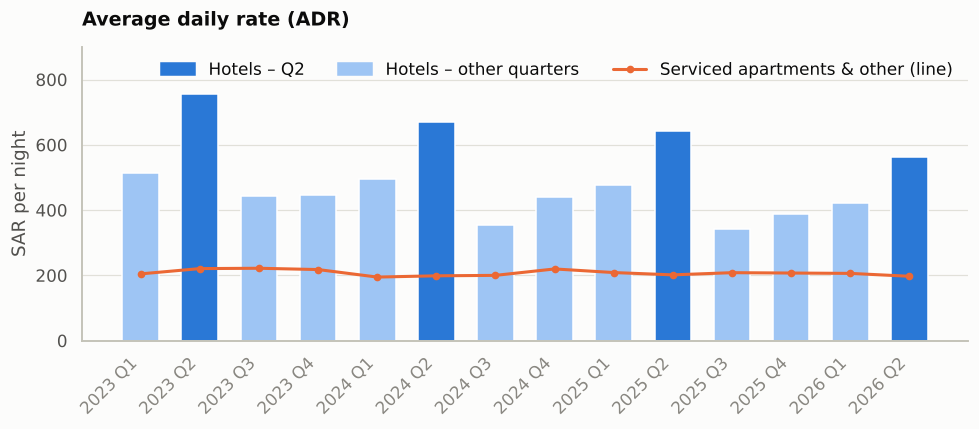

> **What it means for the business:** Hotel ADR is highest in Q2 of every year (Q2 average SAR 658 vs SAR 432 in other quarters, +52%), which matches the Hajj season falling in Q2 during 2023–2026. But the Q2 peak is shrinking: SAR 756 (2023) → 669 → 643 → 563 (2026). Apartment ADR is flat around SAR 208. Hotel revenue per stay depends heavily on one quarter, and that premium is weakening.

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
cols = [BLUE if n == 2 else '#9ec5f4' for n in d.Quarter_Num]
ax.bar(d.Quarter_Label, d.ADR_Hotels, color=cols, width=0.62)
ax.plot(d.Quarter_Label, d.ADR_Apartments, color=ORANGE, lw=2, marker='o', ms=4, label=APT + ' (line)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label='Hotels – Q2'), Patch(color='#9ec5f4', label='Hotels – other quarters'), ax.lines[0]], frameon=False, ncol=3, loc='upper right')
ax.set_title('Average daily rate (ADR)'); ax.set_ylabel('SAR per night'); ax.set_ylim(0, 900)
plt.xticks(rotation=45, ha='right'); finish(ax, '03_adr_trend.png')
q2 = d[d.Quarter_Num == 2].ADR_Hotels; oth = d[d.Quarter_Num != 2].ADR_Hotels
note(f'Hotel ADR is highest in Q2 of every year (Q2 average SAR {q2.mean():,.0f} vs SAR {oth.mean():,.0f} in other quarters, +{pct(q2.mean()/oth.mean()-1, 0)}), which matches the Hajj season falling in Q2 during 2023–2026. But the Q2 peak is shrinking: SAR {q2.iloc[0]:,.0f} (2023) → {q2.iloc[1]:,.0f} → {q2.iloc[2]:,.0f} → {q2.iloc[3]:,.0f} (2026). Apartment ADR is flat around SAR {d.ADR_Apartments.mean():,.0f}. Hotel revenue per stay depends heavily on one quarter, and that premium is weakening.')

## 2. Regional analysis & 3. Occupancy analysis
### 2.1 Hotel occupancy by region

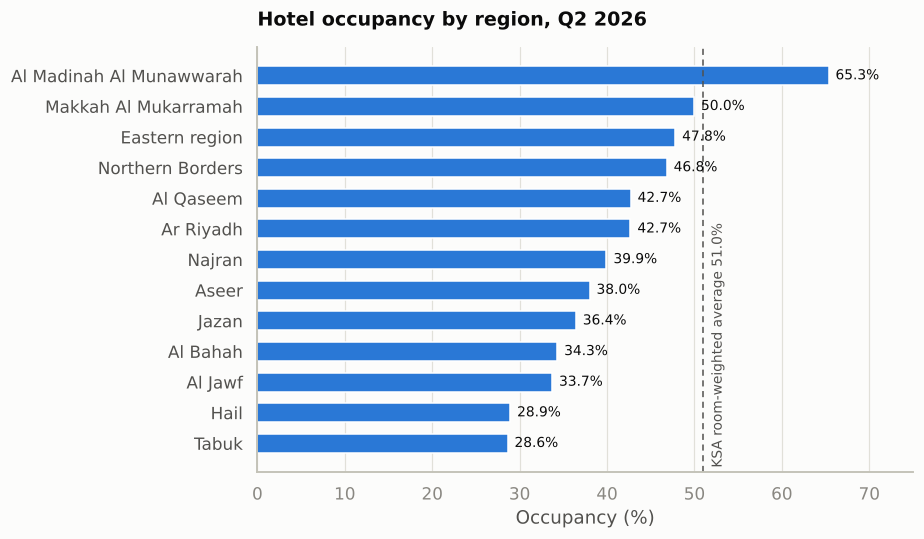

> **What it means for the business:** Al Madinah Al Munawwarah leads at 65.3%, followed by Makkah Al Mukarramah (50.0%) and Eastern region (47.8%). Tabuk (28.6%) and Hail (28.9%) are lowest. Only 1 of 13 regions beat the national room-weighted rate of 51.0%, because the two holy-city regions hold 86% of all hotel rooms and pull the national figure up.

In [5]:
s = rh.Occupancy.sort_values(); nat = (rh.Occupancy*rh.Available_Rooms).sum()/rh.Available_Rooms.sum()
fig, ax = plt.subplots(figsize=(8.5, 5)); ax.barh(s.index, s*100, color=BLUE, height=0.62)
for y, v in enumerate(s): ax.text(v*100+0.8, y, pct(v), va='center', fontsize=9, color=INK)
ax.axvline(nat*100, color=INK2, lw=1, ls=(0, (4, 3))); ax.text(nat*100+0.9, 3.2, f'KSA room-weighted average {pct(nat)}', rotation=90, color=INK2, fontsize=9, va='center')
ax.set_title('Hotel occupancy by region, Q2 2026'); ax.set_xlabel('Occupancy (%)'); ax.set_xlim(0, 75); finish(ax, '04_hotel_occupancy_by_region.png', grid='x')
note(f'{s.index[-1]} leads at {pct(s.iloc[-1])}, followed by {s.index[-2]} ({pct(s.iloc[-2])}) and {s.index[-3]} ({pct(s.iloc[-3])}). {s.index[0]} ({pct(s.iloc[0])}) and {s.index[1]} ({pct(s.iloc[1])}) are lowest. Only {int((s > nat).sum())} of 13 regions beat the national room-weighted rate of {pct(nat)}, because the two holy-city regions hold {pct(rh.loc[["Makkah Al Mukarramah","Al Madinah Al Munawwarah"]].Available_Rooms.sum()/rh.Available_Rooms.sum(), 0)} of all hotel rooms and pull the national figure up.')

### 2.2 Year-on-year change in hotel occupancy

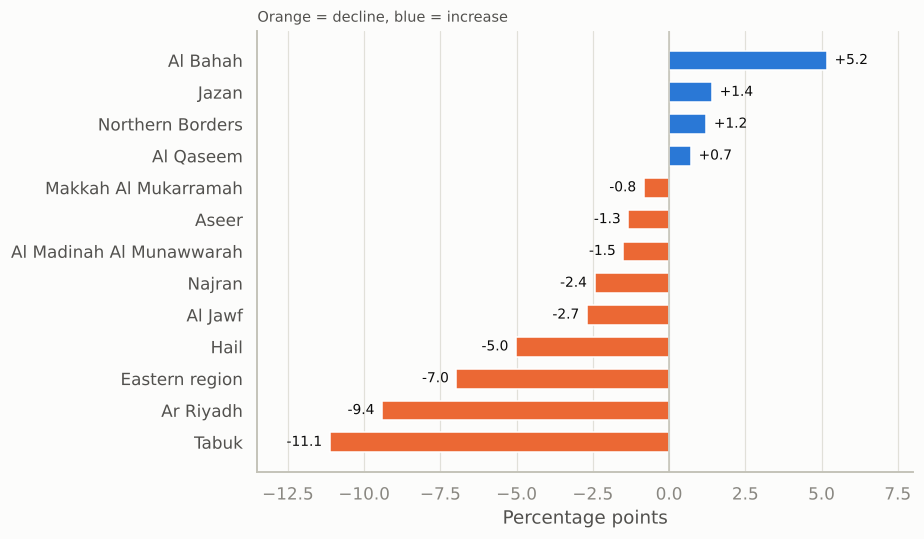

> **What it means for the business:** 9 of 13 regions lost hotel occupancy. The largest drops are Tabuk (-11.1 pts), Ar Riyadh (-9.4 pts) and Eastern region (-7.0 pts); the best improvement is Al Bahah (+5.2 pts). The declines are concentrated in large business and leisure markets, not in the pilgrimage regions (Makkah -0.8, Madinah -1.5).

In [6]:
dlt = ((rh.Occupancy-rh.Occupancy_Q2_2025)*100).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5)); ax.barh(dlt.index, dlt, color=[ORANGE if v < 0 else BLUE for v in dlt], height=0.62)
for y, v in enumerate(dlt): ax.text(v + (0.25 if v >= 0 else -0.25), y, f'{v:+.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9, color=INK)
ax.axvline(0, color='#c3c2b7', lw=1); ax.set_xlim(-13.5, 8); ax.set_title('Hotel occupancy: change Q2 2026 vs Q2 2025'); ax.set_xlabel('Percentage points'); finish(ax, '05_hotel_occupancy_yoy.png', grid='x', sub='Orange = decline, blue = increase')
note(f'{int((dlt < 0).sum())} of 13 regions lost hotel occupancy. The largest drops are {dlt.index[0]} ({dlt.iloc[0]:+.1f} pts), {dlt.index[1]} ({dlt.iloc[1]:+.1f} pts) and {dlt.index[2]} ({dlt.iloc[2]:+.1f} pts); the best improvement is {dlt.index[-1]} ({dlt.iloc[-1]:+.1f} pts). The declines are concentrated in large business and leisure markets, not in the pilgrimage regions (Makkah {dlt["Makkah Al Mukarramah"]:+.1f}, Madinah {dlt["Al Madinah Al Munawwarah"]:+.1f}).')

### 2.3 Where the rooms are (table)

In [7]:
rooms = reg.groupby('Region').Available_Rooms.sum().sort_values(); sh = rooms/rooms.sum()
display(pd.DataFrame({'Available rooms': rooms, 'Share of KSA': sh.map(pct)}).iloc[::-1])
note(f'Room capacity is extremely concentrated: Makkah has {rooms.iloc[-1]:,.0f} rooms ({pct(sh.iloc[-1])} of the Kingdom) and Madinah {pct(sh.iloc[-2])}. Riyadh has the most serviced-apartment facilities but only {pct(sh["Ar Riyadh"])} of rooms. National hospitality KPIs are therefore mostly a Makkah story, and regional results should always be read separately.')

,Available rooms,Share of KSA
Region,,
Makkah Al Mukarramah,393554,63.2%
Al Madinah Al Munawwarah,82858,13.3%
Ar Riyadh,60900,9.8%
Eastern region,32581,5.2%
Aseer,15031,2.4%
Tabuk,10006,1.6%
Jazan,7861,1.3%
Al Qaseem,5425,0.9%
Hail,3905,0.6%


> **What it means for the business:** Room capacity is extremely concentrated: Makkah has 393,554 rooms (63.2% of the Kingdom) and Madinah 13.3%. Riyadh has the most serviced-apartment facilities but only 9.8% of rooms. National hospitality KPIs are therefore mostly a Makkah story, and regional results should always be read separately.

## 4. City analysis

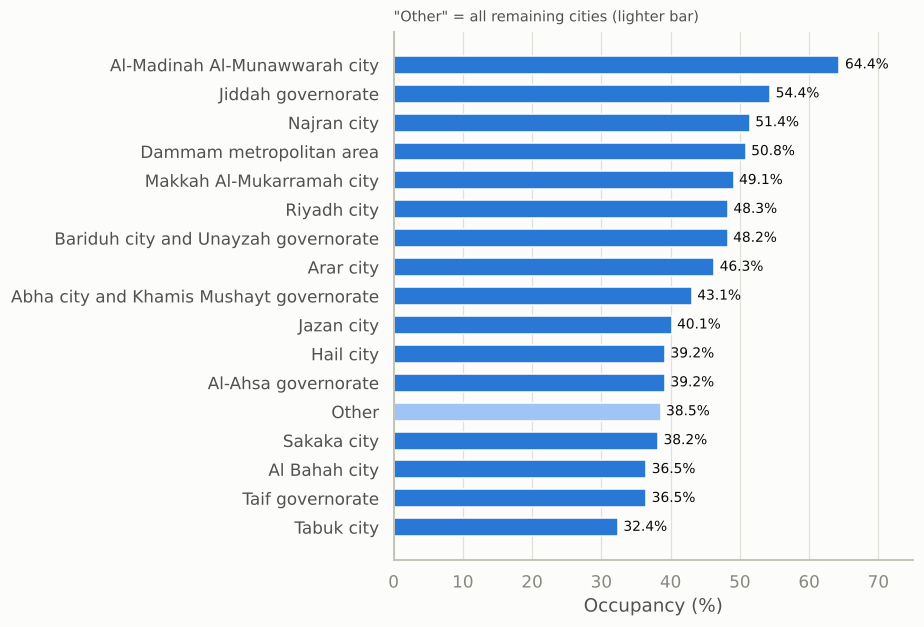

> **What it means for the business:** Occupancy ranges from 32.4% (Tabuk city) to 64.4% (Al-Madinah Al-Munawwarah city), a gap of 32 points. After Madinah come Jiddah governorate (54.4%), Najran city (51.4%) and Dammam metropolitan area (50.8%). Tabuk city and Taif (36.5%) fill only about a third of their rooms in Q2.

In [8]:
ca = city[city.Facility_Type == ALL].set_index('City'); s = ca.Occupancy.sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5.8)); ax.barh(s.index, s*100, color=['#9ec5f4' if i == 'Other' else BLUE for i in s.index], height=0.62)
for y, v in enumerate(s): ax.text(v*100+0.8, y, pct(v), va='center', fontsize=9, color=INK)
ax.set_title('Occupancy by city, all facilities, Q2 2026'); ax.set_xlabel('Occupancy (%)'); ax.set_xlim(0, 75); finish(ax, '06_occupancy_by_city.png', grid='x', sub='"Other" = all remaining cities (lighter bar)')
note(f'Occupancy ranges from {pct(s.iloc[0])} ({s.index[0]}) to {pct(s.iloc[-1])} ({s.index[-1]}), a gap of {(s.iloc[-1]-s.iloc[0])*100:.0f} points. After Madinah come {s.index[-2]} ({pct(s.iloc[-2])}), {s.index[-3]} ({pct(s.iloc[-3])}) and {s.index[-4]} ({pct(s.iloc[-4])}). {s.index[0]} and Taif ({pct(s["Taif governorate"])}) fill only about a third of their rooms in Q2.')

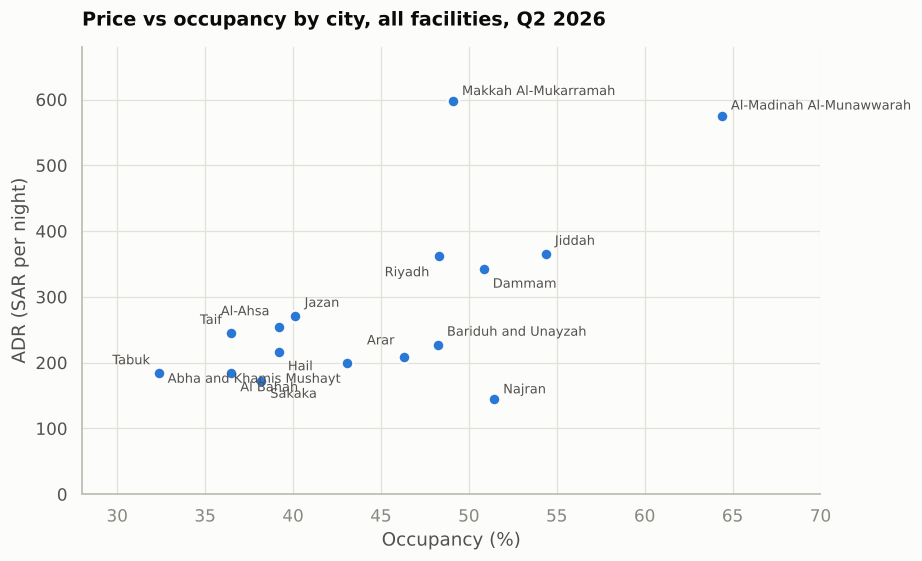

> **What it means for the business:** Three tiers appear. (1) Holy cities: Makkah SAR 598 and Madinah SAR 575, with Madinah also the fullest. (2) Large metros: Jeddah, Riyadh and Dammam at SAR 342–365 and 48–54% occupancy. (3) Secondary cities below SAR 275. Najran city is the cheapest (SAR 144) yet has above-average occupancy (51.4%), so price there is low because of market level, not weak demand. Correlation between ADR and occupancy across cities: 0.66.

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5.2)); c = ca.drop(index='Other')
ax.scatter(c.Occupancy*100, c.ADR, s=60, color=BLUE, edgecolor=SURF, lw=1.5, zorder=3)
off = {'Riyadh city': (-6, -13), 'Dammam metropolitan area': (6, -12), 'Jiddah governorate': (6, 6), 'Sakaka city': (6, -11), 'Al Bahah city': (6, -12), 'Tabuk city': (-6, 6), 'Taif governorate': (-6, 6), 'Hail city': (6, -12), 'Al-Ahsa governorate': (-6, 8), 'Jazan city': (6, 6), 'Arar city': (-6, 8), 'Abha city and Khamis Mushayt governorate': (-4, -13), 'Bariduh city and Unayzah governorate': (6, 6)}
for n, r_ in c.iterrows():
    dx, dy = off.get(n, (6, 4)); ax.annotate(n.replace(' city', '').replace(' governorate', '').replace(' metropolitan area', ''), (r_.Occupancy*100, r_.ADR), textcoords='offset points', xytext=(dx, dy), fontsize=8.5, color=INK2, ha='left' if dx > 0 else 'right')
ax.set_title('Price vs occupancy by city, all facilities, Q2 2026'); ax.set_xlabel('Occupancy (%)'); ax.set_ylabel('ADR (SAR per night)'); ax.set_xlim(28, 70); ax.set_ylim(0, 680); finish(ax, '07_city_adr_vs_occupancy.png', grid='both')
hi = c.ADR.sort_values(ascending=False)
note(f'Three tiers appear. (1) Holy cities: Makkah SAR {c.ADR["Makkah Al-Mukarramah city"]:,.0f} and Madinah SAR {c.ADR["Al-Madinah Al-Munawwarah city"]:,.0f}, with Madinah also the fullest. (2) Large metros: Jeddah, Riyadh and Dammam at SAR {c.ADR["Dammam metropolitan area"]:,.0f}–{c.ADR["Jiddah governorate"]:,.0f} and 48–54% occupancy. (3) Secondary cities below SAR 275. {hi.index[-1]} is the cheapest (SAR {hi.iloc[-1]:,.0f}) yet has above-average occupancy ({pct(c.Occupancy[hi.index[-1]])}), so price there is low because of market level, not weak demand. Correlation between ADR and occupancy across cities: {c.ADR.corr(c.Occupancy):.2f}.')

## 5. ADR analysis by region

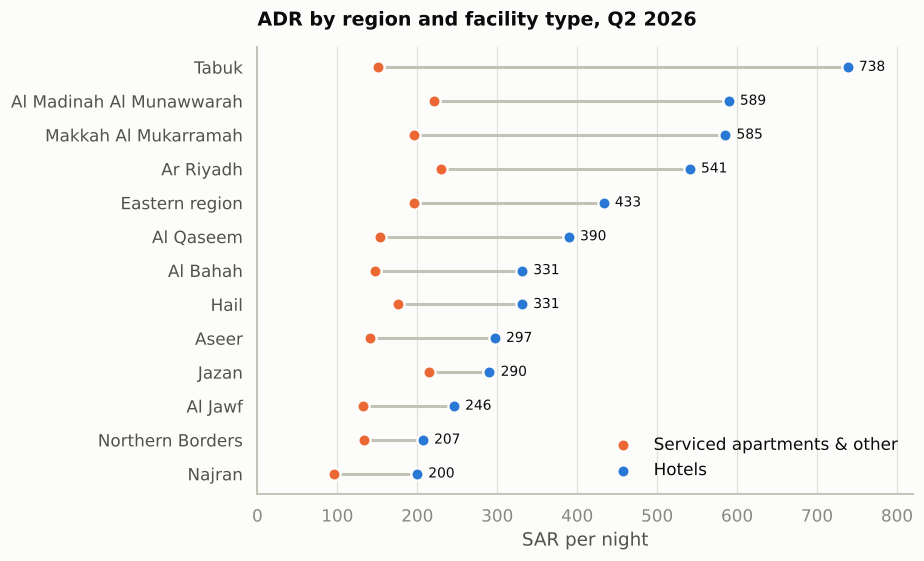

> **What it means for the business:** Hotel ADR spans SAR 200 (Najran) to SAR 738 (Tabuk), a 3.7x gap. Tabuk is the most expensive hotel market but has the lowest occupancy (28.6%), a premium-price / low-volume profile. Hotels charge on average 2.9x the serviced-apartment rate (SAR 573 vs 198, weighted by rooms sold). Hotel ADR fell year-on-year in 11 of 13 regions; the sharpest cuts were Ar Riyadh (-26.8%) and Hail (-25.7%).

In [10]:
o = rh.ADR.sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.hlines(o, ra.ADR[o], rh.ADR[o], color='#c3c2b7', lw=2, zorder=1)
ax.scatter(ra.ADR[o], o, s=64, color=ORANGE, label=APT, zorder=3, edgecolor=SURF, lw=1.5); ax.scatter(rh.ADR[o], o, s=64, color=BLUE, label=HOT, zorder=3, edgecolor=SURF, lw=1.5)
for n in o: ax.text(rh.ADR[n]+14, n, f'{rh.ADR[n]:,.0f}', va='center', fontsize=9, color=INK)
ax.set_title('ADR by region and facility type, Q2 2026'); ax.set_xlabel('SAR per night'); ax.set_xlim(0, 820); ax.legend(frameon=False, loc='lower right'); finish(ax, '08_adr_by_region.png', grid='x')
w = lambda g: (g.ADR*g.Occupancy*g.Available_Rooms).sum()/(g.Occupancy*g.Available_Rooms).sum()
chg = (rh.ADR/rh.ADR_Q2_2025-1).sort_values()
note(f'Hotel ADR spans SAR {rh.ADR.min():,.0f} ({rh.ADR.idxmin()}) to SAR {rh.ADR.max():,.0f} ({rh.ADR.idxmax()}), a {rh.ADR.max()/rh.ADR.min():.1f}x gap. Tabuk is the most expensive hotel market but has the lowest occupancy ({pct(rh.Occupancy["Tabuk"])}), a premium-price / low-volume profile. Hotels charge on average {w(rh)/w(ra):.1f}x the serviced-apartment rate (SAR {w(rh):,.0f} vs {w(ra):,.0f}, weighted by rooms sold). Hotel ADR fell year-on-year in {int((chg < 0).sum())} of 13 regions; the sharpest cuts were {chg.index[0]} ({pct(chg.iloc[0])}) and {chg.index[1]} ({pct(chg.iloc[1])}).')

## 6. Length of stay

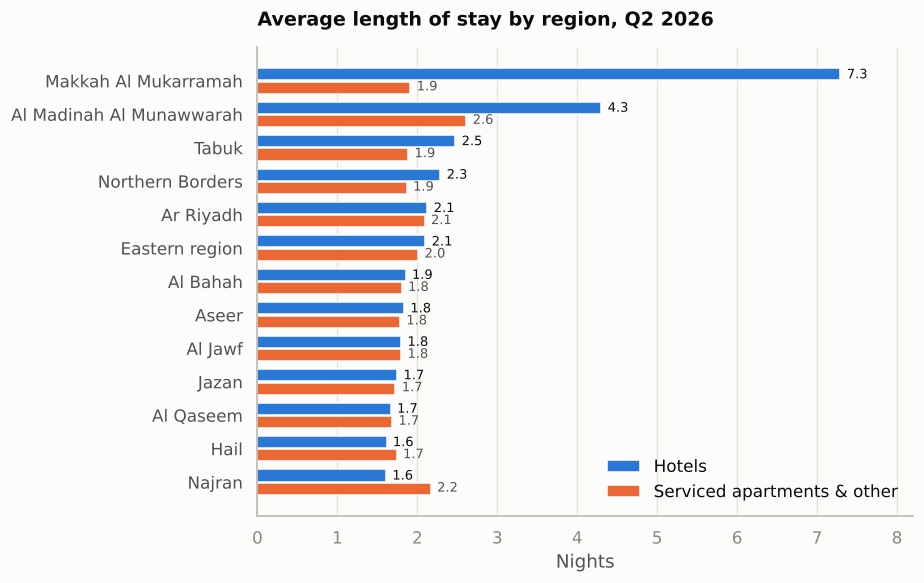

> **What it means for the business:** Nationally, hotel guests stay 5.0 nights and apartment guests 2.1. Makkah hotels are the outlier at 7.3 nights (May alone: 11.9 nights at SAR 963, the Hajj month), then Madinah at 4.3. In the other 11 regions the median hotel stay is only 1.8 nights: short business or transit trips, where revenue growth has to come from extending the stay.

In [11]:
o = rh.ALOS.sort_values().index; y = np.arange(len(o)); h = 0.36
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(y+h/2+0.02, rh.ALOS[o], height=h, color=BLUE, label=HOT); ax.barh(y-h/2-0.02, ra.ALOS[o], height=h, color=ORANGE, label=APT)
for i, n in enumerate(o): ax.text(rh.ALOS[n]+0.08, i+h/2, f'{rh.ALOS[n]:.1f}', va='center', fontsize=8.5, color=INK); ax.text(ra.ALOS[n]+0.08, i-h/2, f'{ra.ALOS[n]:.1f}', va='center', fontsize=8.5, color=INK2)
ax.set_yticks(y, o); ax.set_title('Average length of stay by region, Q2 2026'); ax.set_xlabel('Nights'); ax.set_xlim(0, 8.2); ax.legend(frameon=False, loc='lower right'); finish(ax, '09_length_of_stay_by_region.png', grid='x')
mk = regm[(regm.Region == 'Makkah Al Mukarramah') & (regm.Facility_Type == HOT)].set_index('Month')
note(f'Nationally, hotel guests stay {last.ALOS_Hotels:.1f} nights and apartment guests {last.ALOS_Apartments:.1f}. Makkah hotels are the outlier at {rh.ALOS["Makkah Al Mukarramah"]:.1f} nights (May alone: {mk.ALOS["May"]:.1f} nights at SAR {mk.ADR["May"]:,.0f}, the Hajj month), then Madinah at {rh.ALOS["Al Madinah Al Munawwarah"]:.1f}. In the other 11 regions the median hotel stay is only {rh.ALOS.drop(["Makkah Al Mukarramah","Al Madinah Al Munawwarah"]).median():.1f} nights: short business or transit trips, where revenue growth has to come from extending the stay.')

## 7. Employment

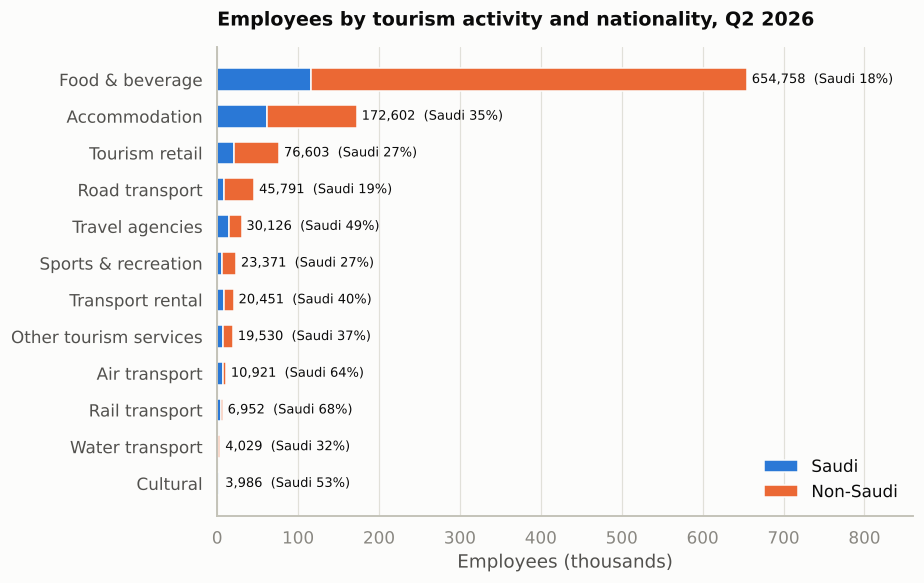

> **What it means for the business:** The sector employs 1,069,120 people; 61.2% work in food & beverage and 16.1% in accommodation. Saudis are 24.1% of the workforce, from 18% in Food & beverage to 68% in Rail transport. Women are 13.2% of all employees but 46.6% of Saudi employees, so Saudi women are already close to half of the national workforce in tourism. Total employment grew 7.2% year-on-year: non-Saudi +8.2%, Saudi +4.2%.

In [12]:
p = ea.pivot_table(index='Activity_Short', columns='Nationality', values='Employees', aggfunc='sum'); p['T'] = p.sum(axis=1); p = p.sort_values('T')
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(p.index, p['Saudi']/1000, color=BLUE, height=0.62, label='Saudi', edgecolor=SURF, lw=1); ax.barh(p.index, p['Non-Saudi']/1000, left=p['Saudi']/1000, color=ORANGE, height=0.62, label='Non-Saudi', edgecolor=SURF, lw=1)
for i, (n, r_) in enumerate(p.iterrows()): ax.text(r_['T']/1000+6, i, f"{r_['T']:,.0f}  (Saudi {pct(r_['Saudi']/r_['T'], 0)})", va='center', fontsize=8.5, color=INK)
ax.set_title('Employees by tourism activity and nationality, Q2 2026'); ax.set_xlabel('Employees (thousands)'); ax.set_xlim(0, 860); ax.legend(frameon=False, loc='lower right'); finish(ax, '10_employment_by_activity.png', grid='x')
tot = ea.Employees.sum(); fem = ea[ea.Gender == 'Female'].Employees.sum(); sau = ea[ea.Nationality == 'Saudi']; sshare = (p['Saudi']/p['T']).sort_values()
note(f'The sector employs {tot:,.0f} people; {pct(p["T"].iloc[-1]/tot)} work in food & beverage and {pct(p["T"].iloc[-2]/tot)} in accommodation. Saudis are {pct(sau.Employees.sum()/tot)} of the workforce, from {pct(sshare.iloc[0], 0)} in {sshare.index[0]} to {pct(sshare.iloc[-1], 0)} in {sshare.index[-1]}. Women are {pct(fem/tot)} of all employees but {pct(sau[sau.Gender == "Female"].Employees.sum()/sau.Employees.sum())} of Saudi employees, so Saudi women are already close to half of the national workforce in tourism. Total employment grew {pct(last.Total_Employees/yago.Total_Employees-1)} year-on-year: non-Saudi +{pct(last.NonSaudi_Employees/yago.NonSaudi_Employees-1)}, Saudi +{pct(last.Saudi_Employees/yago.Saudi_Employees-1)}.')

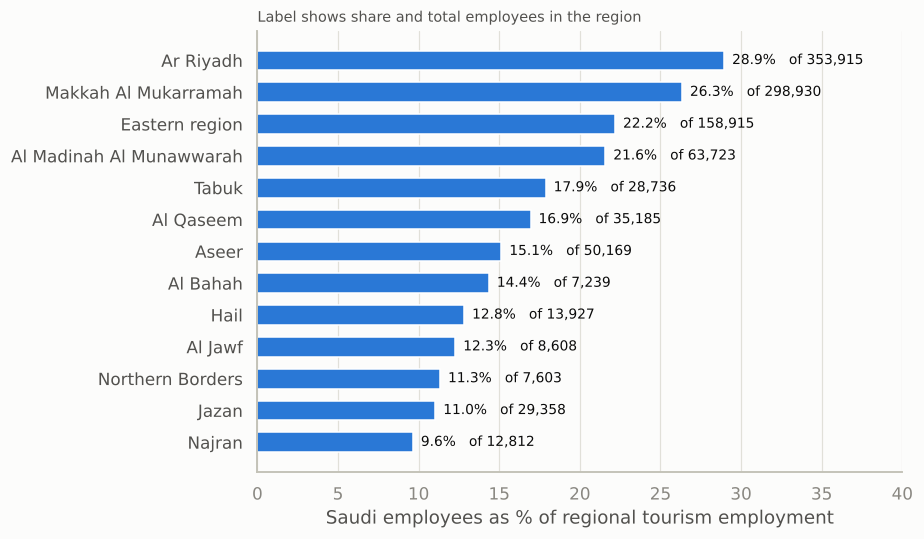

> **What it means for the business:** Three regions hold 75.9% of tourism jobs: Ar Riyadh (353,915), Makkah Al Mukarramah (298,930) and Eastern region (158,915). Saudi participation is highest where the market is largest (Ar Riyadh 28.9%) and lowest in smaller southern and northern regions (Najran 9.6%, Jazan 11.0%).

In [13]:
e = er.pivot_table(index='Region', columns='Nationality', values='Employees', aggfunc='sum'); e['T'] = e.sum(axis=1); e['S'] = e['Saudi']/e['T']; e = e.sort_values('S')
fig, ax = plt.subplots(figsize=(8.5, 5)); ax.barh(e.index, e.S*100, color=BLUE, height=0.62)
for i, (n, r_) in enumerate(e.iterrows()): ax.text(r_.S*100+0.5, i, f"{pct(r_.S)}   of {r_['T']:,.0f}", va='center', fontsize=9, color=INK)
ax.set_title('Saudi share of tourism employees by region, Q2 2026'); ax.set_xlabel('Saudi employees as % of regional tourism employment'); ax.set_xlim(0, 40); finish(ax, '11_saudization_by_region.png', grid='x', sub='Label shows share and total employees in the region')
top3 = e['T'].sort_values(ascending=False).head(3)
note(f'Three regions hold {pct(top3.sum()/e["T"].sum())} of tourism jobs: {top3.index[0]} ({top3.iloc[0]:,.0f}), {top3.index[1]} ({top3.iloc[1]:,.0f}) and {top3.index[2]} ({top3.iloc[2]:,.0f}). Saudi participation is highest where the market is largest ({e.index[-1]} {pct(e.S.iloc[-1])}) and lowest in smaller southern and northern regions ({e.index[0]} {pct(e.S.iloc[0])}, {e.index[1]} {pct(e.S.iloc[1])}).')

## 8. Establishments

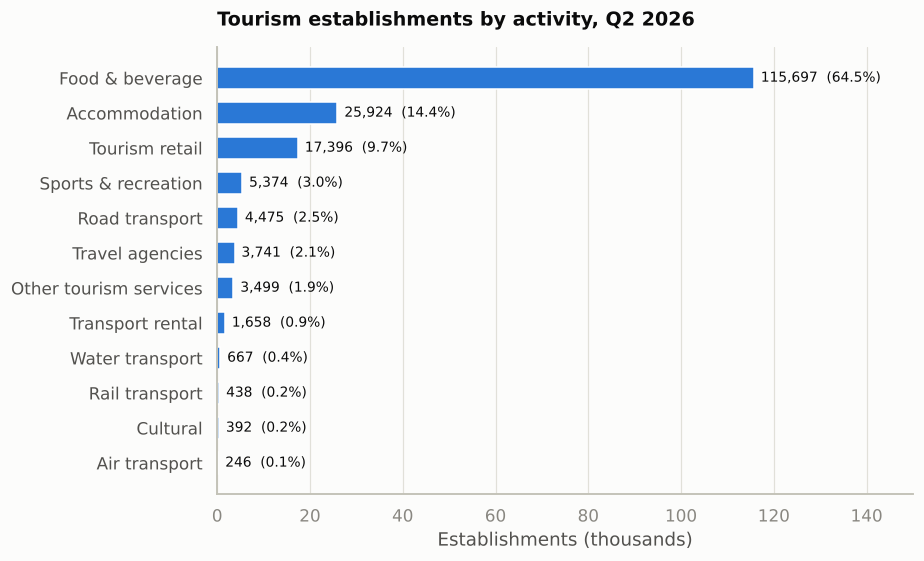

> **What it means for the business:** Food & beverage is 64.5% of all establishments (115,697), followed by accommodation (14.4%) and tourism retail (9.7%); these three are 88.6% of the base. By region, Makkah Al Mukarramah (25.8%) and Ar Riyadh (25.4%) are almost equal and together with Eastern region hold 65.2%. Average size differs a lot: Air transport has 44 employees per establishment and Rail transport 16, against 5.7 in food & beverage, a sector of many small businesses.

In [14]:
a = sa.set_index('Activity_Short').Establishments.sort_values(); t = a.sum()
fig, ax = plt.subplots(figsize=(8.5, 5.2)); ax.barh(a.index, a/1000, color=BLUE, height=0.62)
for i, v in enumerate(a): ax.text(v/1000+1.5, i, f'{v:,.0f}  ({pct(v/t)})', va='center', fontsize=9, color=INK)
ax.set_title('Tourism establishments by activity, Q2 2026'); ax.set_xlabel('Establishments (thousands)'); ax.set_xlim(0, 150); finish(ax, '12_establishments_by_activity.png', grid='x')
emp = ea.groupby('Activity_Short').Employees.sum(); per = (emp/sa.set_index('Activity_Short').Establishments).sort_values()
rs = sr.set_index('Region').Establishments.sort_values(ascending=False)
note(f'Food & beverage is {pct(a.iloc[-1]/t)} of all establishments ({a.iloc[-1]:,.0f}), followed by accommodation ({pct(a["Accommodation"]/t)}) and tourism retail ({pct(a["Tourism retail"]/t)}); these three are {pct((a.iloc[-1]+a["Accommodation"]+a["Tourism retail"])/t)} of the base. By region, {rs.index[0]} ({pct(rs.iloc[0]/rs.sum())}) and {rs.index[1]} ({pct(rs.iloc[1]/rs.sum())}) are almost equal and together with {rs.index[2]} hold {pct(rs.head(3).sum()/rs.sum())}. Average size differs a lot: {per.index[-1]} has {per.iloc[-1]:,.0f} employees per establishment and {per.index[-2]} {per.iloc[-2]:,.0f}, against {per["Food & beverage"]:.1f} in food & beverage, a sector of many small businesses.')

## Summary of observations
Generated from the data (numbers are recomputed each run).

In [15]:
obs = [
 f'Tourism establishments grew from {q.Tourism_Establishments.iloc[0]:,.0f} (Q1 2022) to {last.Tourism_Establishments:,.0f} (Q2 2026), +{pct(g_total)}; year-on-year growth is +{pct(g_yoy)}.',
 f'Licensed hospitality facilities more than doubled in 9 quarters: {q.Licensed_Facilities.dropna().iloc[0]:,.0f} (Q1 2024) to {last.Licensed_Facilities:,.0f} (+{pct(last.Licensed_Facilities/q.Licensed_Facilities.dropna().iloc[0]-1, 0)}).',
 f'Hotel occupancy fell to {pct(last.Occupancy_Hotels)} from {pct(yago.Occupancy_Hotels)} a year earlier; apartment occupancy is at a series low of {pct(last.Occupancy_Apartments)}.',
 f'Hotel ADR peaks every Q2 but the peak declined from SAR {q2.iloc[0]:,.0f} (2023) to SAR {q2.iloc[3]:,.0f} (2026), a {pct(1-q2.iloc[3]/q2.iloc[0])} decline.',
 f'Makkah holds {pct(sh.iloc[-1])} of available rooms; Makkah + Madinah hold {pct(sh.iloc[-1]+sh.iloc[-2])}.',
 f'Hotel occupancy by region ranges {pct(rh.Occupancy.min())} ({rh.Occupancy.idxmin()}) to {pct(rh.Occupancy.max())} ({rh.Occupancy.idxmax()}); {int((dlt < 0).sum())} of 13 regions declined year-on-year, Tabuk most ({dlt["Tabuk"]:+.1f} pts).',
 f'Riyadh hotel ADR dropped {pct(1-rh.ADR["Ar Riyadh"]/rh.ADR_Q2_2025["Ar Riyadh"])} year-on-year (SAR {rh.ADR_Q2_2025["Ar Riyadh"]:,.0f} to {rh.ADR["Ar Riyadh"]:,.0f}) together with a {dlt["Ar Riyadh"]:+.1f} pt occupancy change.',
 f'Makkah hotel stays average {rh.ALOS["Makkah Al Mukarramah"]:.1f} nights versus a median of {rh.ALOS.drop(["Makkah Al Mukarramah","Al Madinah Al Munawwarah"]).median():.1f} nights in the 11 non-pilgrimage regions.',
 f'Food & beverage accounts for {pct(a.iloc[-1]/t)} of establishments and {pct(p["T"].iloc[-1]/tot)} of employees.',
 f'Saudis are {pct(sau.Employees.sum()/tot)} of tourism employees; women are {pct(fem/tot)} overall but {pct(sau[sau.Gender == "Female"].Employees.sum()/sau.Employees.sum())} of Saudi employees.',
]
display(Markdown('\n'.join(f'{i}. {o_}' for i, o_ in enumerate(obs, 1))))

1. Tourism establishments grew from 109,681 (Q1 2022) to 179,507 (Q2 2026), +63.7%; year-on-year growth is +8.7%.
2. Licensed hospitality facilities more than doubled in 9 quarters: 2,802 (Q1 2024) to 6,278 (+124%).
3. Hotel occupancy fell to 51.0% from 53.2% a year earlier; apartment occupancy is at a series low of 46.5%.
4. Hotel ADR peaks every Q2 but the peak declined from SAR 756 (2023) to SAR 563 (2026), a 25.5% decline.
5. Makkah holds 63.2% of available rooms; Makkah + Madinah hold 76.5%.
6. Hotel occupancy by region ranges 28.6% (Tabuk) to 65.3% (Al Madinah Al Munawwarah); 9 of 13 regions declined year-on-year, Tabuk most (-11.1 pts).
7. Riyadh hotel ADR dropped 26.8% year-on-year (SAR 739 to 541) together with a -9.4 pt occupancy change.
8. Makkah hotel stays average 7.3 nights versus a median of 1.8 nights in the 11 non-pilgrimage regions.
9. Food & beverage accounts for 64.5% of establishments and 61.2% of employees.
10. Saudis are 24.1% of tourism employees; women are 13.2% overall but 46.6% of Saudi employees.

## Data gaps and limits of this analysis
- Regional, city, employment and establishment tables exist for **Q2 2026 only**; the only regional comparison over time is Q2 2025 vs Q2 2026 for occupancy, ADR and length of stay.
- National series start at different dates (establishments 2022, KPIs and employment 2023, licensed facilities 2024), so long-run comparisons are limited to 14 quarters at most.
- Q2 contains Hajj in every year covered, so Q2 values are **not representative of a normal quarter** for Makkah and Madinah.
- City data has no room counts, so city averages cannot be weighted or summed to regions; the `Other` row mixes many small cities.
- No revenue, demand (room-nights sold) or visitor-origin data: RevPAR is approximated as occupancy x ADR in notebook 03.
- Explanations of *why* a number moved are hypotheses; the data shows what changed, not the cause.